In [442]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [443]:
df = pd.read_csv("../data/raw/Car details v3.csv")

In [444]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


### Target Column is: selling_price

```
name -> اسم العربية و نوعها بالضبط
year -> سنة اصدار العربية
selling_price -> سعر العربية (دا الي عايزين نتوقعه)
km_driven -> العربية ماشية قد ايه
fuel -> نوع التفويل
seller_type -> نوع البائع: واحد عادي ولا تاجر
transmission -> اوتوماتيك ولا مانويل
owner -> المالك الكام للعربية
mileage -> العربية بتحرق قد ايه
engine -> كام سي سي
max_power -> قوة العربية
torque -> التورك
seats -> كام راكب
```

In [445]:
df.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1536,Mahindra Renault Logan 1.4 GLX Petrol,2009,135000,120000,Petrol,Individual,Manual,First Owner,15.7 kmpl,1390 CC,75 bhp,"11@ 3,000(kgm@ rpm)",5.0
6434,Volkswagen CrossPolo 1.5 TDI,2014,300000,84000,Diesel,Individual,Manual,Second Owner,20.14 kmpl,1498 CC,88.5 bhp,230Nm@ 1500-2500rpm,5.0
1452,Maruti Swift Dzire Tour LDI,2017,520000,28832,Diesel,Dealer,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
4574,Mahindra Verito 1.5 D4 BSIV,2018,750000,22000,Diesel,Individual,Manual,First Owner,21.03 kmpl,1461 CC,65 bhp,160Nm@ 2000rpm,5.0
1097,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0


In [446]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [447]:
df.shape

(8128, 13)

In [448]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,8128.0,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
seats,7907.0,5.416719,0.959588,2.0,5.0,5.0,5.0,14.0


In [449]:
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [450]:
df.duplicated().sum()

np.int64(1202)

In [451]:
df.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1085,Honda Jazz VX,2016,550000,56494,Petrol,Trustmark Dealer,Manual,First Owner,18.2 kmpl,1199 CC,88.7 bhp,110Nm@ 4800rpm,5.0
5776,Ford EcoSport 1.5 TDCi Trend Plus BSIV,2015,551000,110000,Diesel,Individual,Manual,First Owner,22.77 kmpl,1498 CC,98.59 bhp,205Nm@ 1750-3250rpm,5.0
3557,Maruti Baleno Zeta Automatic,2018,740000,9000,Petrol,Individual,Automatic,First Owner,21.4 kmpl,1197 CC,83.1 bhp,115Nm@ 4000rpm,5.0
7906,Toyota Innova Crysta 2.8 ZX AT BSIV,2016,1516000,120000,Diesel,Individual,Automatic,First Owner,11.36 kmpl,2755 CC,171.5 bhp,360Nm@ 1200-3400rpm,7.0
1648,Nissan Terrano XL 85 PS,2015,480000,60000,Diesel,Individual,Manual,Third Owner,20.45 kmpl,1461 CC,83.8 bhp,200Nm@ 1900rpm,5.0


### هناخد نسخه نعدل عليها براحتنا

In [452]:
df_clean = df.copy()

In [453]:
df_clean = df_clean.drop_duplicates()

In [454]:
df_clean.duplicated().sum()

np.int64(0)

In [455]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   str    
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   str    
 5   seller_type    6926 non-null   str    
 6   transmission   6926 non-null   str    
 7   owner          6926 non-null   str    
 8   mileage        6718 non-null   str    
 9   engine         6718 non-null   str    
 10  max_power      6721 non-null   str    
 11  torque         6717 non-null   str    
 12  seats          6718 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 757.5 KB


In [456]:
df_clean.shape

(6926, 13)

In [457]:
df_clean.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

In [458]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
2367,Mahindra Bolero 2011-2019 SLX,2012,450000,120000,Diesel,Individual,Manual,First Owner,15.96 kmpl,2523 CC,62.1 bhp,195Nm@ 1400-2200rpm,7.0
1979,BMW X1 sDrive20d M Sport,2018,3350000,18000,Diesel,Dealer,Automatic,First Owner,19.62 kmpl,1998 CC,190 bhp,400nm@ 1750-2500rpm,5.0
5903,Maruti Baleno Alpha 1.3,2017,680000,71000,Diesel,Individual,Manual,First Owner,27.39 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1232,Chevrolet Spark 1.0 LT,2012,130000,110000,Petrol,Individual,Manual,First Owner,16.2 kmpl,995 CC,62.1 bhp,90.3Nm@ 4200rpm,5.0
1315,Honda Civic 1.8 V MT,2008,375000,90000,Petrol,Individual,Manual,Third Owner,13.5 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0


for columns mileage, engine and max_power they are strings. We will convert it to float and int.

for mileage there is two units: kmpl and km/kg, we will drop the rows with km/kg, because they are only 88 rows of out 6000+ rows

In [459]:
df_clean['mileage'].str.contains('km/kg').sum()

np.int64(87)

deleted all rows that use km/kg and not petrol and diesel to make consistency in data to use only kmpl and petrol and diesel fuel عشان اسهل علي نفسي

In [460]:
df_clean = df_clean[~df_clean['mileage'].str.contains('km/kg', na=False)]
df_clean = df_clean[df_clean['fuel'].isin(['Petrol', 'Diesel'])]

In [461]:
df_clean['mileage'].str.contains('km/kg').sum()

np.int64(0)

In [462]:
print(df_clean['fuel'].value_counts()) 
print(df_clean['mileage'].str.contains('km/kg', na=False).sum())
print(df_clean.shape)    

fuel
Diesel    3755
Petrol    3077
Name: count, dtype: int64
0
(6832, 13)


In [463]:
df_clean['mileage_kmpl'] = df_clean['mileage'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

In [464]:
df_clean['engine_cc'] = df_clean['engine'].str.extract(r'(\d+\.?\d*)')[0].astype(float).astype('Int64')

In [465]:
df_clean['max_power_bhp'] = df_clean['max_power'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

In [466]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_kmpl,engine_cc,max_power_bhp
5170,Toyota Innova 2.5 G (Diesel) 8 Seater,2014,720000,80000,Diesel,Individual,Manual,Second Owner,12.99 kmpl,2494 CC,100.6 bhp,200Nm@ 1400-3400rpm,8.0,12.99,2494,100.6
5473,Honda City 2017-2020 GXi,2007,210000,120000,Petrol,Individual,Manual,Second Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,17.70,1497,78.0
5796,Volkswagen Passat 1.8 TSI MT,2010,300000,120000,Petrol,Individual,Manual,Second Owner,14.3 kmpl,1798 CC,160 bhp,250Nm@ 1500~4500rpm,5.0,14.30,1798,160.0
1379,Maruti 800 DX 5 Speed,2001,75000,35000,Petrol,Individual,Manual,Third Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0,16.10,796,37.0
2626,Maruti Swift Dzire VDI Optional,2015,525000,80000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,26.59,1248,74.0


In [467]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6832 entries, 0 to 8125
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6832 non-null   str    
 1   year           6832 non-null   int64  
 2   selling_price  6832 non-null   int64  
 3   km_driven      6832 non-null   int64  
 4   fuel           6832 non-null   str    
 5   seller_type    6832 non-null   str    
 6   transmission   6832 non-null   str    
 7   owner          6832 non-null   str    
 8   mileage        6631 non-null   str    
 9   engine         6631 non-null   str    
 10  max_power      6634 non-null   str    
 11  torque         6631 non-null   str    
 12  seats          6631 non-null   float64
 13  mileage_kmpl   6631 non-null   float64
 14  engine_cc      6631 non-null   Int64  
 15  max_power_bhp  6634 non-null   float64
dtypes: Int64(1), float64(3), int64(3), str(9)
memory usage: 914.0 KB


In [468]:
df_clean = df_clean.drop(columns=['mileage', 'engine', 'max_power'])

In [469]:
df_clean.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,torque,seats,mileage_kmpl,engine_cc,max_power_bhp
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,190Nm@ 2000rpm,5.0,23.40,1248,74.00
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,250Nm@ 1500-2500rpm,5.0,21.14,1498,103.52
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,"12.7@ 2,700(kgm@ rpm)",5.0,17.70,1497,78.00
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,22.4 kgm at 1750-2750rpm,5.0,23.00,1396,90.00
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,"11.5@ 4,500(kgm@ rpm)",5.0,16.10,1298,88.20


In [470]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6832 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6832 non-null   str    
 1   year           6832 non-null   int64  
 2   selling_price  6832 non-null   int64  
 3   km_driven      6832 non-null   int64  
 4   fuel           6832 non-null   str    
 5   seller_type    6832 non-null   str    
 6   transmission   6832 non-null   str    
 7   owner          6832 non-null   str    
 8   torque         6631 non-null   str    
 9   seats          6631 non-null   float64
 10  mileage_kmpl   6631 non-null   float64
 11  engine_cc      6631 non-null   Int64  
 12  max_power_bhp  6634 non-null   float64
dtypes: Int64(1), float64(3), int64(3), str(6)
memory usage: 753.9 KB


عملت دروب للتورك عشان كان حوار اننا نحوله لي رقم

In [471]:
df_clean = df_clean.drop(columns=['torque'])

In [472]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6832 entries, 0 to 8125
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6832 non-null   str    
 1   year           6832 non-null   int64  
 2   selling_price  6832 non-null   int64  
 3   km_driven      6832 non-null   int64  
 4   fuel           6832 non-null   str    
 5   seller_type    6832 non-null   str    
 6   transmission   6832 non-null   str    
 7   owner          6832 non-null   str    
 8   seats          6631 non-null   float64
 9   mileage_kmpl   6631 non-null   float64
 10  engine_cc      6631 non-null   Int64  
 11  max_power_bhp  6634 non-null   float64
dtypes: Int64(1), float64(3), int64(3), str(5)
memory usage: 700.5 KB


In [473]:
df_clean.sample(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp
3491,Maruti Alto 800 VXI,2018,310000,10000,Petrol,Individual,Manual,First Owner,5.0,24.70,796,47.30
5981,Maruti Ertiga VDI,2012,560000,200000,Diesel,Individual,Manual,Second Owner,7.0,20.77,1248,88.76
4112,Tata Sumo SE Plus BSII,2000,95000,120000,Diesel,Individual,Manual,Fourth & Above Owner,10.0,12.20,1948,68.00
5817,Maruti Swift 1.3 VXi,2009,180000,50000,Petrol,Individual,Manual,First Owner,NaN,NaN,<NA>,NaN
7015,Hyundai i10 Magna 1.2 iTech SE,2008,140000,60000,Petrol,Individual,Manual,Second Owner,5.0,20.36,1197,78.90


In [474]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
year,6832.0,2013.433109,4.065728,1983.0,2011.0,2014.0,2017.0,2020.0
selling_price,6832.0,520809.824649,522281.607721,29999.0,250000.0,409999.0,640000.0,10000000.0
km_driven,6832.0,73949.502049,58494.426509,1000.0,39000.0,70000.0,100000.0,2360457.0
seats,6631.0,5.440054,0.988312,2.0,5.0,5.0,5.0,14.0
mileage_kmpl,6631.0,19.434536,4.011447,0.0,16.8,19.4,22.32,42.0
engine_cc,6631.0,1435.693259,494.553445,624.0,1197.0,1248.0,1498.0,3604.0
max_power_bhp,6634.0,88.079131,31.796546,0.0,68.0,81.86,100.0,400.0


In [475]:
df_clean.nunique()

name             2018
year               28
selling_price     670
km_driven         915
fuel                2
seller_type         3
transmission        2
owner               5
seats               9
mileage_kmpl      366
engine_cc         121
max_power_bhp     307
dtype: int64

In name column we will extract only the first word which is the brand only not all the car name to decrease the number of unique values

In [476]:
df_clean['brand'] = df_clean['name'].str.split().str[0]

In [477]:
df_clean.nunique()

name             2018
year               28
selling_price     670
km_driven         915
fuel                2
seller_type         3
transmission        2
owner               5
seats               9
mileage_kmpl      366
engine_cc         121
max_power_bhp     307
brand              32
dtype: int64

In [478]:
df_clean = df_clean.drop(columns=['name'])

In [479]:
df_clean['car_age'] = 2026 - df_clean['year']

In [480]:
df_clean.sample(5)

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp,brand,car_age
2523,2015,229999,34000,Petrol,Individual,Manual,Second Owner,5.0,21.10,814,55.20,Hyundai,11
7280,2015,585000,72000,Diesel,Dealer,Manual,First Owner,5.0,22.54,1396,88.73,Hyundai,11
5708,2014,240000,90000,Petrol,Individual,Manual,Second Owner,5.0,23.95,998,67.05,Maruti,12
691,2009,114999,90000,Petrol,Individual,Manual,Fourth & Above Owner,5.0,17.92,1086,62.10,Hyundai,17
56,2016,950000,99000,Diesel,Dealer,Manual,First Owner,7.0,12.99,2494,100.60,Toyota,10


### handle missing values
```
since the percentage of missinge values are low we will impute not deletion
seat -> impute with mode
mileage, engine, max power -> impute with median
```

In [481]:
(df_clean.isnull().sum() / len(df_clean)) * 100

year             0.000000
selling_price    0.000000
km_driven        0.000000
fuel             0.000000
seller_type      0.000000
transmission     0.000000
owner            0.000000
seats            2.942037
mileage_kmpl     2.942037
engine_cc        2.942037
max_power_bhp    2.898126
brand            0.000000
car_age          0.000000
dtype: float64

In [482]:
df_clean['seats'] = df_clean['seats'].fillna(df_clean['seats'].mode()[0])

In [483]:
df_clean.columns

Index(['year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'seats', 'mileage_kmpl', 'engine_cc',
       'max_power_bhp', 'brand', 'car_age'],
      dtype='str')

in mileage_kmpl and max_power_bhp there was many zero values for many rows, so we assume they are NaN values to treat it like missing.

In [484]:
df_clean['mileage_kmpl'] = df_clean['mileage_kmpl'].replace(0, np.nan)
df_clean['max_power_bhp'] = df_clean['max_power_bhp'].replace(0, np.nan)

In [485]:
cols = ['mileage_kmpl', 'engine_cc', 'max_power_bhp']

for col in cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [486]:
df_clean.isnull().sum()

year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
seats            0
mileage_kmpl     0
engine_cc        0
max_power_bhp    0
brand            0
car_age          0
dtype: int64

### Handlings Outliers

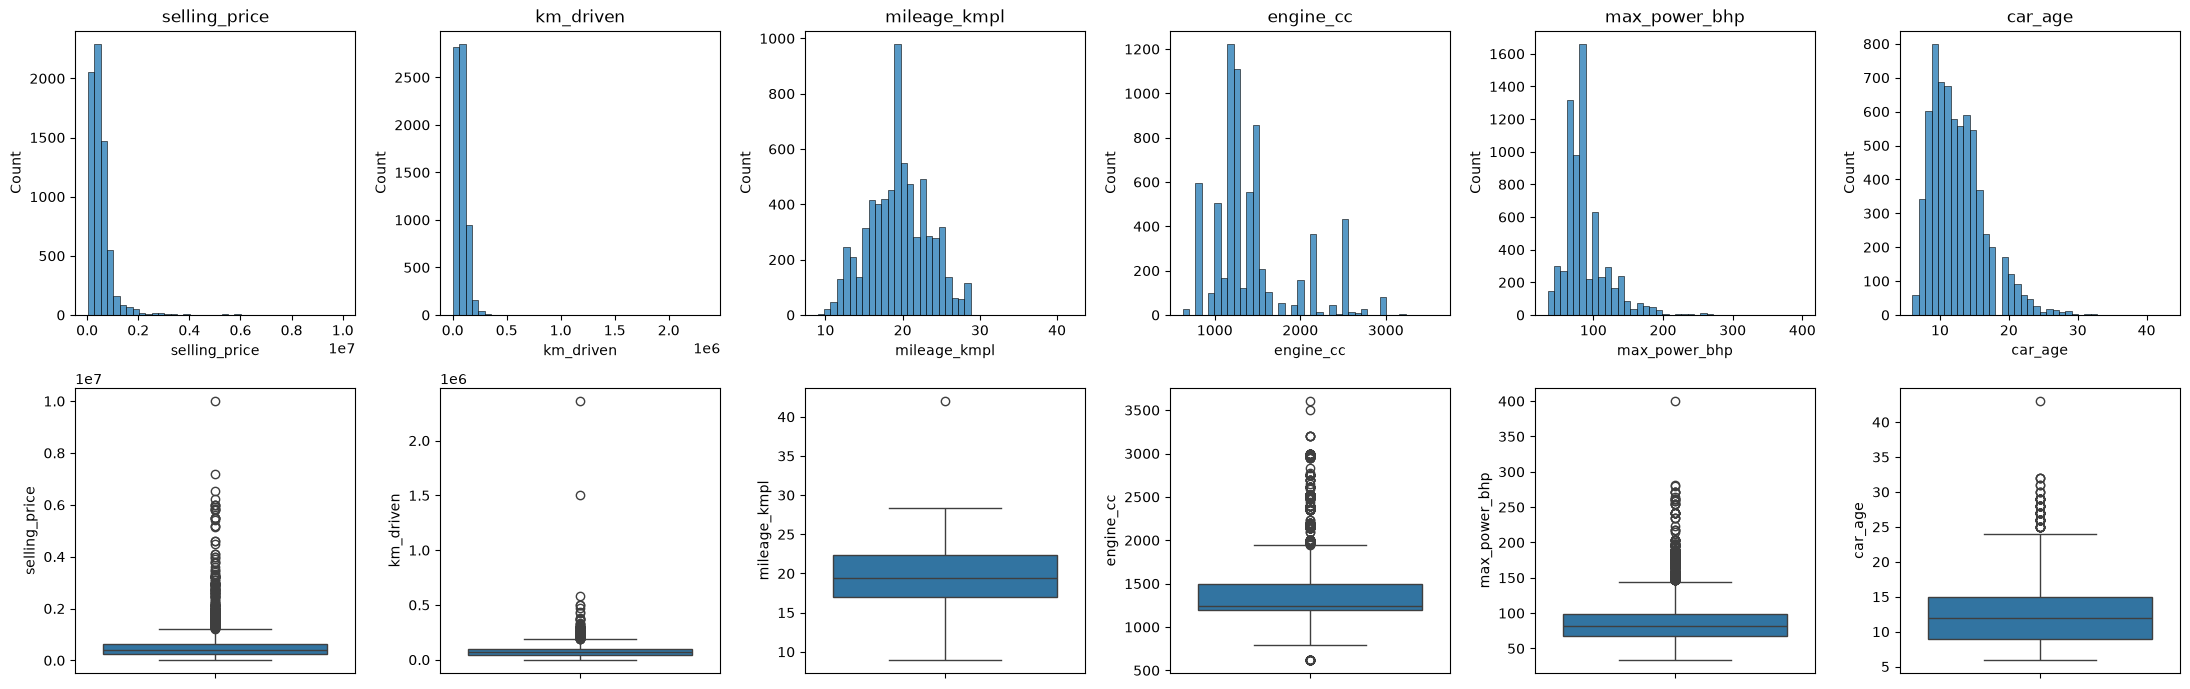

,count,mean,std,min,1%,5%,95%,99%,max
selling_price,6832.0,520809.824649,522281.607721,29999.0,50000.0,100000.0,1200000.0,2737910.0,10000000.0
km_driven,6832.0,73949.502049,58494.426509,1000.0,5000.0,12000.0,156986.25,236966.97,2360457.0
mileage_kmpl,6832.0,19.476114,3.845405,9.0,11.4,12.99,25.8,28.4,42.0
engine_cc,6832.0,1430.171253,488.25447,624.0,796.0,796.0,2499.0,2956.0,3604.0
max_power_bhp,6832.0,87.934838,31.295776,34.2,37.0,47.3,147.8,190.0,400.0
car_age,6832.0,12.566891,4.065728,6.0,7.0,7.0,20.0,25.0,43.0


In [487]:
num_cols = ['selling_price', 'km_driven', 'mileage_kmpl', 'engine_cc', 'max_power_bhp', 'car_age']

fig, axes = plt.subplots(2, len(num_cols), figsize=(22, 7))
for i, col in enumerate(num_cols):
    sns.histplot(df_clean[col], bins=40, ax=axes[0, i])
    sns.boxplot(y=df_clean[col], ax=axes[1, i])
    axes[0, i].set_title(col)
plt.tight_layout()
plt.show()

df_clean[num_cols].describe(percentiles=[.01, .05, .95, .99]).T

In [488]:
for col in num_cols:
    q1, q3 = df_clean[col].quantile([.25, .75])
    iqr = q3 - q1
    mask = (df_clean[col] < q1 - 1.5*iqr) | (df_clean[col] > q3 + 1.5*iqr)
    print(f"{col:15} outliers: {mask.sum():5}  ({mask.mean()*100:.1f}%)  skew: {df_clean[col].skew():.2f}")

selling_price   outliers:   323  (4.7%)  skew: 5.55
km_driven       outliers:   164  (2.4%)  skew: 11.82
mileage_kmpl    outliers:     1  (0.0%)  skew: 0.03
engine_cc       outliers:  1207  (17.7%)  skew: 1.25
max_power_bhp   outliers:   371  (5.4%)  skew: 1.75
car_age         outliers:    74  (1.1%)  skew: 1.00
